# Exploratory Data Analysis — Order Cancellation

This notebook explores the `pedidos` dataset used by the three models (Decision Tree, Random Forest and XGBoost).

**Data source.** The notebook uses `data/raw/` when the full files are present and falls back to the versioned sample in `data/sample/` otherwise. The outputs stored in this notebook were generated with the **sample** (5,000 labelled orders), so rates and counts here are estimates and will differ slightly from the full 100k dataset.

**Goal.** Understand the target, the features and their relationship with cancellation *before* modelling — and spot anything suspicious (leakage, missing values, duplicates).

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score

pd.set_option("display.max_columns", 40)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25})

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
raw = ROOT / "data" / "raw" / "pedidos_completo_100k.csv"
sample = ROOT / "data" / "sample" / "pedidos_completo_sample.csv"
path = raw if raw.exists() else sample
df = pd.read_csv(path, parse_dates=["data_pedido"])
print(f"Source: {path.relative_to(ROOT)}  |  shape: {df.shape}")

Source: data/sample/pedidos_completo_sample.csv  |  shape: (5000, 31)


## 1. Overview and data quality

In [2]:
quality = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "nulls": df.isna().sum(),
    "unique": df.nunique(),
})
display(quality)
print("Duplicated order IDs:", df["id_pedido"].duplicated().sum())
print("Duplicated rows (ignoring ID):", df.drop(columns="id_pedido").duplicated().sum())
print("Order dates:", df["data_pedido"].min().date(), "->", df["data_pedido"].max().date())

,dtype,nulls,unique
id_pedido,int64,0,5000
data_pedido,datetime64[us],0,545
hora_pedido,int64,0,24
dia_semana,int64,0,7
valor_pedido,float64,0,4756
quantidade_itens,int64,0,10
categoria_produto,str,0,10
forma_pagamento,str,0,4
parcelas,int64,0,12
canal_venda,str,0,3


Duplicated order IDs: 0
Duplicated rows (ignoring ID): 0
Order dates: 2024-01-01 -> 2025-06-28


## 2. Target: `cancelado`

cancelado
0    3225
1    1775

Cancellation rate: 35.5%


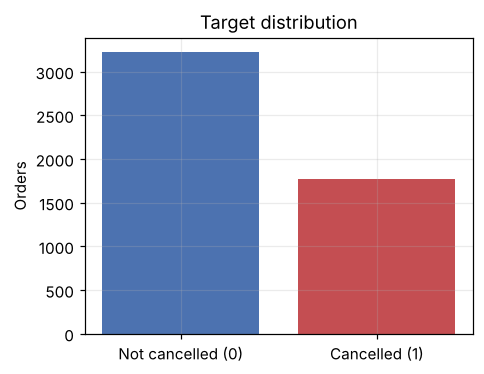

In [3]:
target_counts = df["cancelado"].value_counts().sort_index()
print(target_counts.to_string())
print(f"\nCancellation rate: {df['cancelado'].mean():.1%}")

fig, ax = plt.subplots(figsize=(4.5, 3.5))
ax.bar(["Not cancelled (0)", "Cancelled (1)"], target_counts.values, color=["#4C72B0", "#C44E52"])
ax.set_ylabel("Orders"); ax.set_title("Target distribution")
plt.tight_layout(); plt.show()

The classes are imbalanced, but only moderately — the minority class is a large share of the data. This is why the models use class weighting (`class_weight='balanced'` / `scale_pos_weight`) rather than resampling.

## 3. Categorical features vs. cancellation

Dashed line = overall cancellation rate.

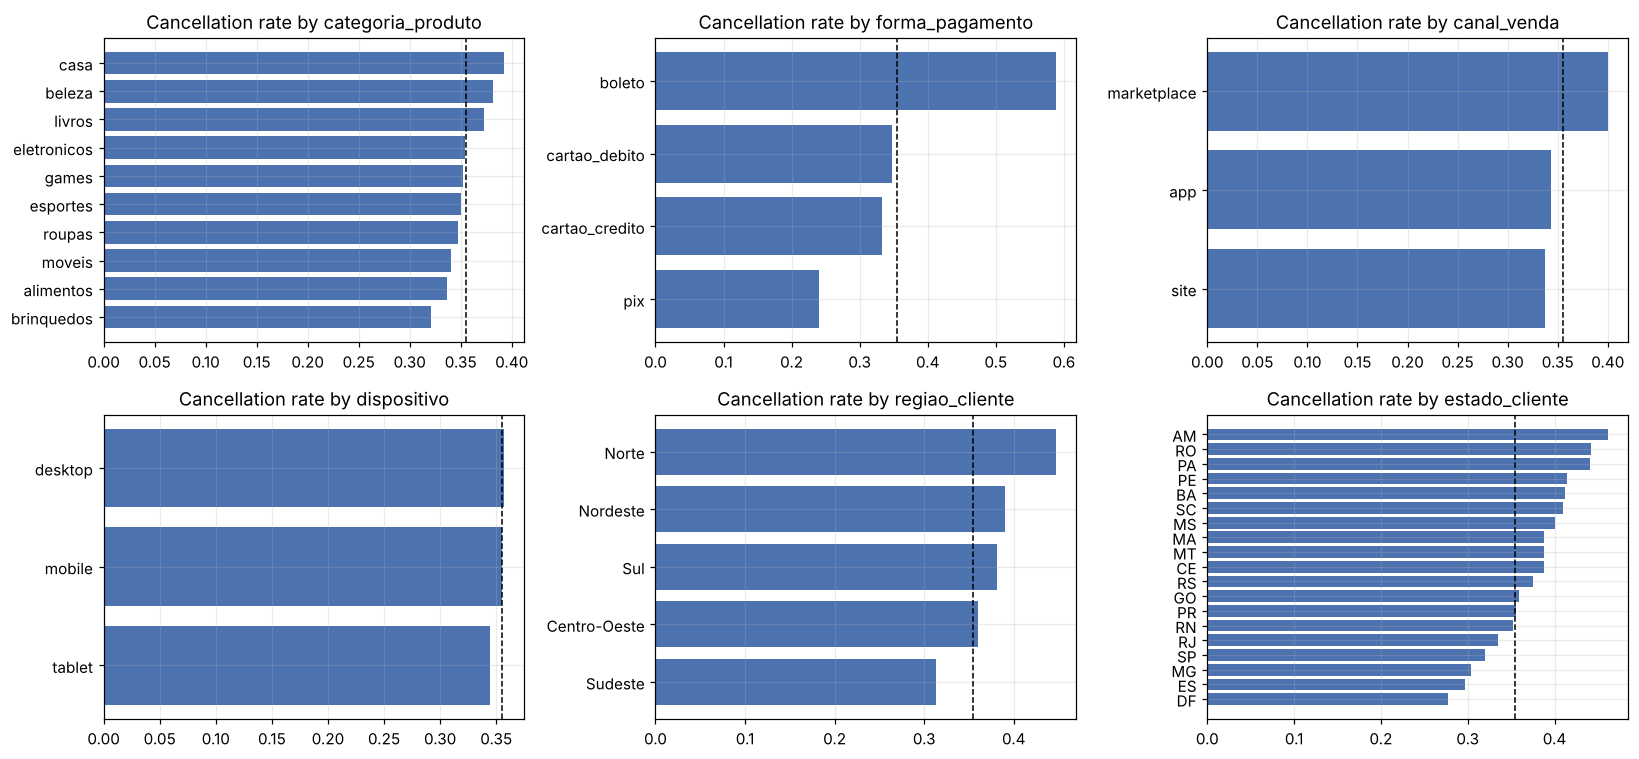

In [4]:
cat_cols = [c for c in df.select_dtypes(exclude="number").columns if c != "data_pedido"]
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, col in zip(axes.ravel(), cat_cols):
    rate = df.groupby(col)["cancelado"].mean().sort_values()
    ax.barh(rate.index.astype(str), rate.values, color="#4C72B0")
    ax.axvline(df["cancelado"].mean(), color="k", ls="--", lw=1)
    ax.set_title(f"Cancellation rate by {col}")
for ax in axes.ravel()[len(cat_cols):]:
    ax.axis("off")
plt.tight_layout(); plt.show()

## 4. Binary flags vs. cancellation

In [5]:
bool_cols = [c for c in df.columns if set(df[c].dropna().unique()) <= {0, 1} and c != "cancelado"]
rates = {c: df.groupby(c)["cancelado"].mean() for c in bool_cols}
tbl = pd.DataFrame({c: {"rate if 0": r.get(0, np.nan), "rate if 1": r.get(1, np.nan), "share of 1s": df[c].mean()} for c, r in rates.items()}).T
tbl["difference"] = tbl["rate if 1"] - tbl["rate if 0"]
display(tbl.round(3).sort_values("difference", key=abs, ascending=False))

,rate if 0,rate if 1,share of 1s,difference
estoque_disponivel_no_ato,0.670,0.334,0.938,-0.336
cliente_novo,0.264,0.506,0.377,0.242
abriu_chamado_suporte,0.328,0.563,0.115,0.235
endereco_entrega_diferente_cobranca,0.340,0.440,0.149,0.100
cupom_desconto,0.366,0.335,0.351,-0.031
frete_gratis,0.353,0.358,0.449,0.005


## 5. Numeric features vs. cancellation

*Univariate AUC* measures how well a single feature ranks cancelled vs. non-cancelled orders on its own (0.5 = no signal, 1.0 = perfect). It is a quick **leakage check**: a single feature with an AUC close to 1.0 would be suspicious. It also shows how much signal is spread across several weak features.

In [6]:
num_cols = [c for c in df.select_dtypes("number").columns
            if c not in ("id_pedido", "cancelado") and c not in bool_cols]
summary = df.groupby("cancelado")[num_cols].median().T
summary.columns = ["median (not cancelled)", "median (cancelled)"]
summary["univariate AUC"] = [
    max(roc_auc_score(df["cancelado"], df[c]), 1 - roc_auc_score(df["cancelado"], df[c])) for c in num_cols
]
display(summary.round(3).sort_values("univariate AUC", ascending=False))

,median (not cancelled),median (cancelled),univariate AUC
num_compras_anteriores,3.000,0.00,0.630
tempo_aprovacao_pagamento_horas,0.320,0.46,0.596
distancia_km,170.800,218.30,0.568
prazo_entrega_dias,6.000,6.00,0.562
avaliacoes_cliente,4.000,3.90,0.546
hora_pedido,12.000,11.00,0.530
parcelas,1.000,1.00,0.521
desconto_percentual,0.000,0.00,0.517
ticket_medio_cliente,264.630,252.83,0.513
valor_pedido,367.690,380.62,0.513


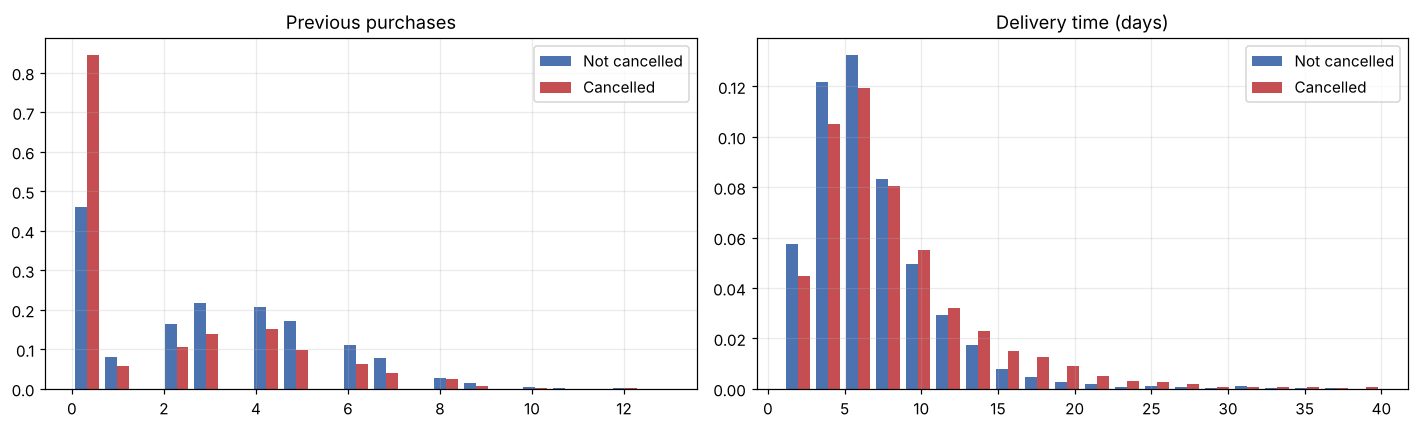

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, (col, label) in zip(axes, [("num_compras_anteriores", "Previous purchases"), ("prazo_entrega_dias", "Delivery time (days)")]):
    ax.hist([df.loc[df.cancelado == 0, col], df.loc[df.cancelado == 1, col]], bins=20,
            label=["Not cancelled", "Cancelled"], color=["#4C72B0", "#C44E52"], density=True)
    ax.set_title(label); ax.legend()
plt.tight_layout(); plt.show()

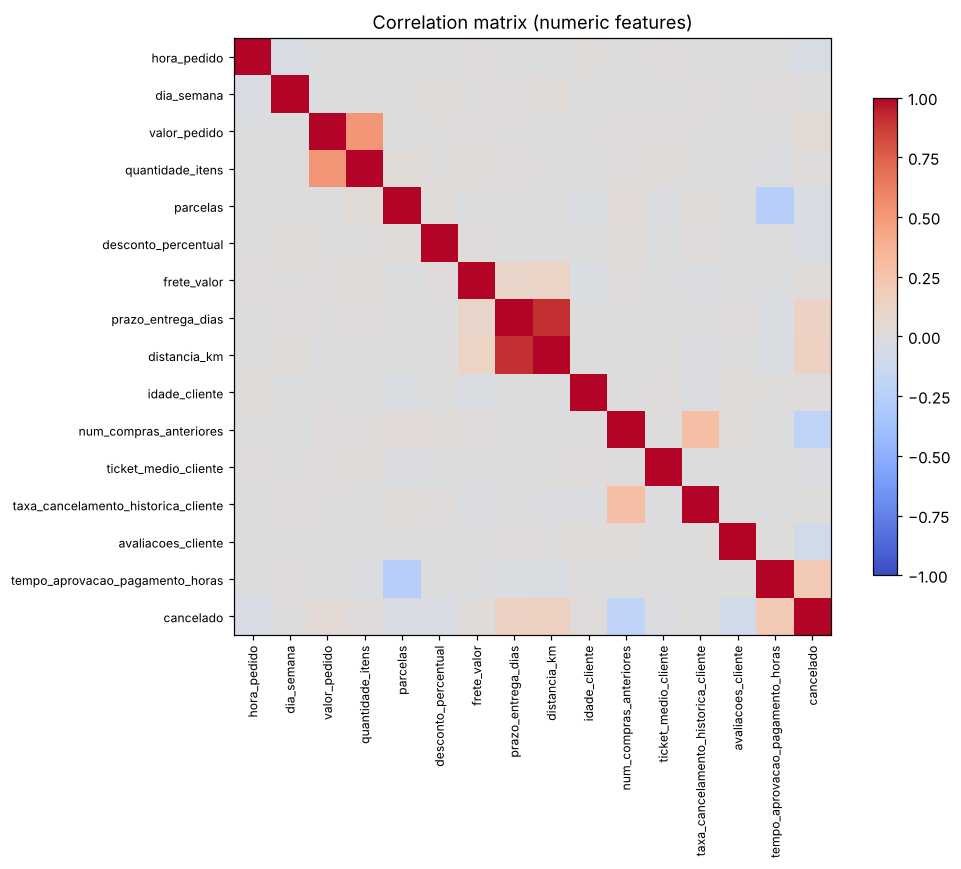

Strongest absolute pairwise correlations (excluding the diagonal):
prazo_entrega_dias               distancia_km                           0.908
valor_pedido                     quantidade_itens                       0.508
num_compras_anteriores           taxa_cancelamento_historica_cliente    0.288
parcelas                         tempo_aprovacao_pagamento_horas        0.260
tempo_aprovacao_pagamento_horas  cancelado                              0.209


In [8]:
corr = df[num_cols + ["cancelado"]].corr()
fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=90, fontsize=8)
ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.columns, fontsize=8)
ax.grid(False); fig.colorbar(im, ax=ax, shrink=0.8); ax.set_title("Correlation matrix (numeric features)")
plt.tight_layout(); plt.show()
print("Strongest absolute pairwise correlations (excluding the diagonal):")
pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack().abs().sort_values(ascending=False).head(5)
print(pairs.round(3).to_string())

## 6. Time patterns

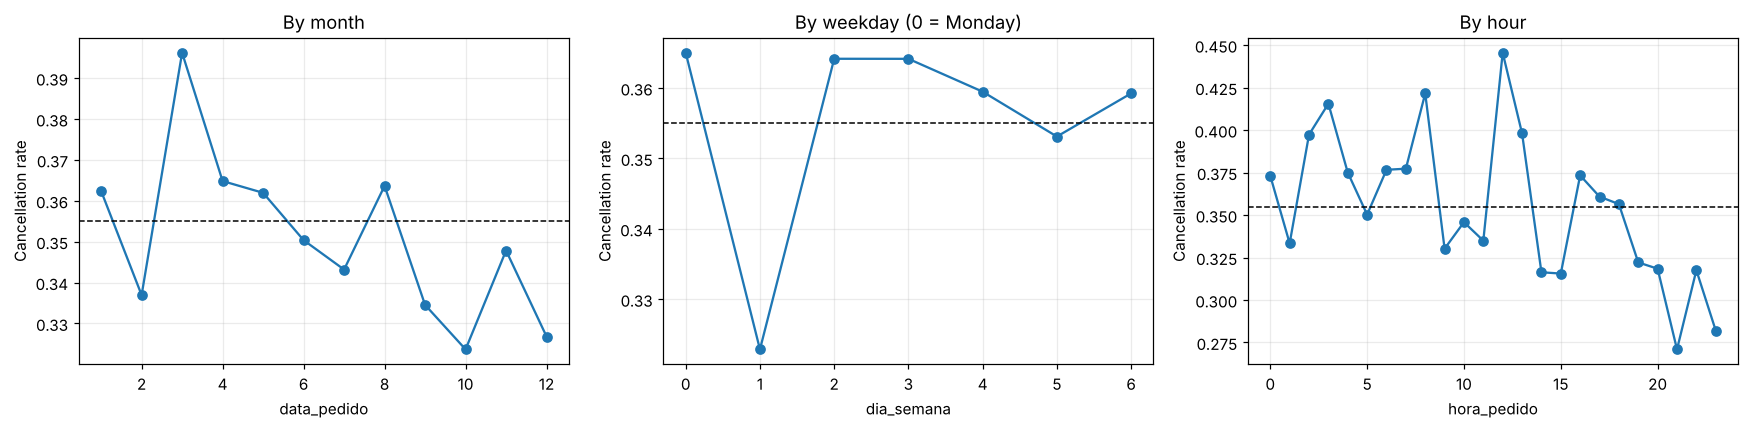

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
df.groupby(df["data_pedido"].dt.month)["cancelado"].mean().plot(ax=axes[0], marker="o"); axes[0].set_title("By month")
df.groupby("dia_semana")["cancelado"].mean().plot(ax=axes[1], marker="o"); axes[1].set_title("By weekday (0 = Monday)")
df.groupby("hora_pedido")["cancelado"].mean().plot(ax=axes[2], marker="o"); axes[2].set_title("By hour")
for ax in axes:
    ax.axhline(df["cancelado"].mean(), color="k", ls="--", lw=1); ax.set_ylabel("Cancellation rate")
plt.tight_layout(); plt.show()

## 7. Conclusions and points to validate

Figures below refer to the 5,000-row sample stored in this notebook's outputs; they are estimates, not exact values for the full 100k dataset (the sample is stratified, so the overall cancellation rate of 35.5% is the same by construction).

- **Data quality:** no missing values, no duplicated order IDs and no duplicated rows in this dataset. Dates cover 2024-01-01 to 2025-06-28.
- **Strongest binary signals:** orders placed with `estoque_disponivel_no_ato = 0` were cancelled about 67% of the time (vs. about 33% when stock was available); new customers about 51% (vs. about 26%); orders followed by a support ticket about 56% (vs. about 33%); and orders with a delivery address different from the billing address about 44% (vs. about 34%). Coupon use and free shipping show almost no difference.
- **No dominant feature:** the best single-feature AUC is about 0.63 (`num_compras_anteriores`), so the signal is spread across several weak features and there is no sign of a single feature that "gives away" the target.
- **Redundant features:** `prazo_entrega_dias` and `distancia_km` are strongly correlated (about 0.91). Tree-based models tolerate this, but their feature importances can be split between the two.
- **To validate with the data owner (cannot be decided from the data alone):** whether `abriu_chamado_suporte`, `tempo_aprovacao_pagamento_horas`, `estoque_disponivel_no_ato` and `taxa_cancelamento_historica_cliente` are *known at the moment the prediction would be used*. If any of them is only recorded after the cancellation happens, it would be target leakage by timing and the model's real-world performance would be lower than the test metrics suggest.
- **Time:** order dates are spread over the same period in the labelled and the new data, so the train/test split used by the models is random (stratified), not temporal; the project therefore does not measure performance on future periods.